## Task 1


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# Task 1.1: ডেটাফ্রেম (DataFrame) তৈরি করা
# ==========================================

data_task1 = {
    'ID': [1, 2, 3, 4, 5, 6, 7, 8],
    'Age': [12, 25, 47, 33, 56, 80, 21, 39]
}

# Pandas DataFrame তৈরি করা
df_task1 = pd.DataFrame(data_task1)

# ডেটাফ্রেমটি প্রিন্ট করে দেখা
print("Task 1 - Initial Dataset:")
print(df_task1)
print("\n\n")


Task 1 - Initial Dataset:
   ID  Age
0   1   12
1   2   25
2   3   47
3   4   33
4   5   56
5   6   80
6   7   21
7   8   39





In [2]:
# ==========================================
# Task 1.2: Bin Edges এবং Labels ঠিক করা
# ==========================================

bins = [0, 18, 35, 60, 100]

labels = ['Child/Teen', 'Young Adult', 'Middle-Aged', 'Senior']

print("Defined Bin Edges:", bins)
print("Defined Labels:", labels)

Defined Bin Edges: [0, 18, 35, 60, 100]
Defined Labels: ['Child/Teen', 'Young Adult', 'Middle-Aged', 'Senior']


In [3]:
# ==========================================
# Task 1.3: pd.cut() ফাংশন ব্যবহার করে Age গ্রুপে ভাগ করা
# ==========================================

df_task1['Age_Group'] = pd.cut(df_task1['Age'], bins=bins, labels=labels)

print("Dataset after Binning:")
print(df_task1)

Dataset after Binning:
   ID  Age    Age_Group
0   1   12   Child/Teen
1   2   25  Young Adult
2   3   47  Middle-Aged
3   4   33  Young Adult
4   5   56  Middle-Aged
5   6   80       Senior
6   7   21  Young Adult
7   8   39  Middle-Aged


In [4]:
# ==========================================
# Task 1.4: প্রতিটি গ্রুপের ফ্রিকোয়েন্সি (value_counts) বের করা
# ==========================================

age_group_counts = df_task1['Age_Group'].value_counts(sort=False)

print("Frequency of each Age Group:")
print(age_group_counts)

Frequency of each Age Group:
Age_Group
Child/Teen     1
Young Adult    3
Middle-Aged    3
Senior         1
Name: count, dtype: int64


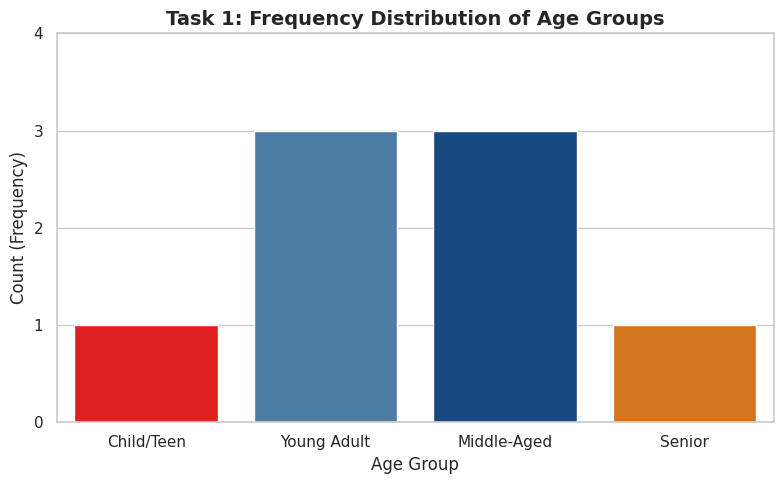

In [5]:
# ==========================================
# Task 1.5: Frequency Plot
# ==========================================
plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values,
    palette=['#FF0000', '#3E7CB1', '#054A91', '#F17300']
)

plt.title('Task 1: Frequency Distribution of Age Groups', fontsize=14, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Count (Frequency)', fontsize=12)
plt.yticks(range(0, 5)) # Y-axis এ পূর্ণসংখ্যা (0, 1, 2, 3, 4) দেখানোর জন্য

plt.tight_layout()
plt.show()

## Task 2


In [6]:
# ==========================================
# Task 2.1: DataFrame
# ==========================================

data_task2 = {
    'ID': [1, 2, 3, 4, 5, 6],
    'Exam_Score': [65, 70, 82, 90, 55, 73]
}

# Pandas DataFrame
df_task2 = pd.DataFrame(data_task2)

print("Task 2 - Initial Dataset:")
print(df_task2)

Task 2 - Initial Dataset:
   ID  Exam_Score
0   1          65
1   2          70
2   3          82
3   4          90
4   5          55
5   6          73


In [7]:
# ==========================================
# Task 2.2: Mean (μ) and Standard Deviation (σ)
# ==========================================
# Mean
mean_score = df_task2['Exam_Score'].mean()

# আদর্শ বিচ্যুতি / Standard Deviation
std_score = df_task2['Exam_Score'].std()

print(f"Mean (μ) of Exam Score: {mean_score:.2f}")
print(f"Standard Deviation (σ) of Exam Score: {std_score:.2f}")

Mean (μ) of Exam Score: 72.50
Standard Deviation (σ) of Exam Score: 12.37


In [8]:
# ==========================================
# Task 2.3: Standardize Exam Score using the Z-Score formula
# ==========================================
# Apply formula: z = (x - μ) / σ
df_task2['Z_Score'] = (df_task2['Exam_Score'] - mean_score) / std_score

# Print the dataset with standardized values
print("Task 2 - Dataset with Standardized Z-Scores:")
print(df_task2)

Task 2 - Dataset with Standardized Z-Scores:
   ID  Exam_Score   Z_Score
0   1          65 -0.606141
1   2          70 -0.202047
2   3          82  0.767779
3   4          90  1.414329
4   5          55 -1.414329
5   6          73  0.040409


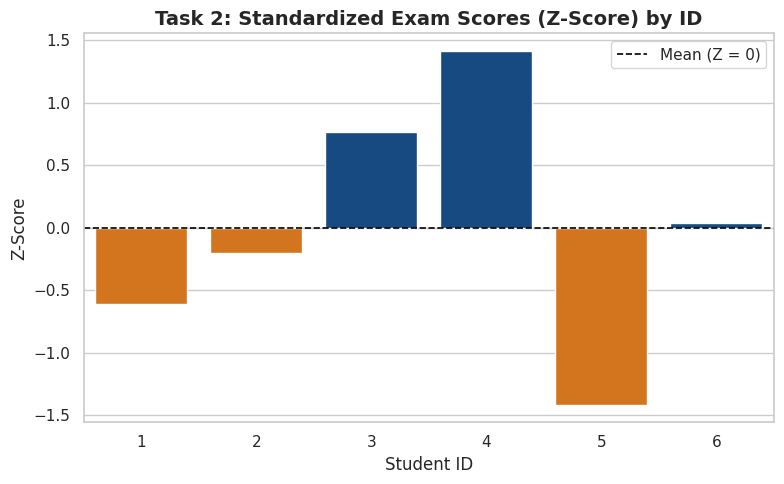

In [9]:
# ==========================================
# Task 2.4: Plot the Standardized Z-Scores
# ==========================================
plt.figure(figsize=(8, 5))

# Set colors: Deep Blue for positive Z-scores, Orange for negative Z-scores
colors = ['#F17300' if z < 0 else '#054A91' for z in df_task2['Z_Score']]

# Create a bar plot of Z-Scores for each ID
sns.barplot(
    x=df_task2['ID'],
    y=df_task2['Z_Score'],
    palette=colors
)

# Add a horizontal reference line at Mean (Z = 0)
plt.axhline(0, color='black', linestyle='--', linewidth=1.2, label='Mean (Z = 0)')

plt.title('Task 2: Standardized Exam Scores (Z-Score) by ID', fontsize=14, fontweight='bold')
plt.xlabel('Student ID', fontsize=12)
plt.ylabel('Z-Score', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()


## Task 3


In [10]:
# ==========================================
# Task 3.1: Apply Label Encoding using LabelEncoder()
# ==========================================

data_task3 = {
    'ID': [1, 2, 3, 4, 5, 6],
    'Color': ['Red', 'Blue', 'Green', 'Red', 'Green', 'Blue']
}

df_task3 = pd.DataFrame(data_task3)

print("Task 3 - Initial Dataset:")
print(df_task3)
print("-" * 40)


# Create a copy for Label Encoding
df_label_encoded = df_task3.copy()

# Initialize LabelEncoder and fit_transform the 'Color' column
label_encoder = LabelEncoder()
df_label_encoded['Color_Label'] = label_encoder.fit_transform(df_label_encoded['Color'])

# Display the Label Encoded dataset
print("Task 3 - Label Encoded Dataset:")
print(df_label_encoded)


Task 3 - Initial Dataset:
   ID  Color
0   1    Red
1   2   Blue
2   3  Green
3   4    Red
4   5  Green
5   6   Blue
----------------------------------------
Task 3 - Label Encoded Dataset:
   ID  Color  Color_Label
0   1    Red            2
1   2   Blue            0
2   3  Green            1
3   4    Red            2
4   5  Green            1
5   6   Blue            0


In [11]:
# ==========================================
# Task 3.2: Apply One-Hot Encoding using pd.get_dummies()
# ==========================================
df_onehot_encoded = pd.get_dummies(df_task3, columns=['Color'], dtype=int)

print("Task 3 - One-Hot Encoded Dataset:")
display(df_onehot_encoded)

Task 3 - One-Hot Encoded Dataset:


,ID,Color_Blue,Color_Green,Color_Red
0,1,0,0,1
1,2,1,0,0
2,3,0,1,0
3,4,0,0,1
4,5,0,1,0
5,6,1,0,0


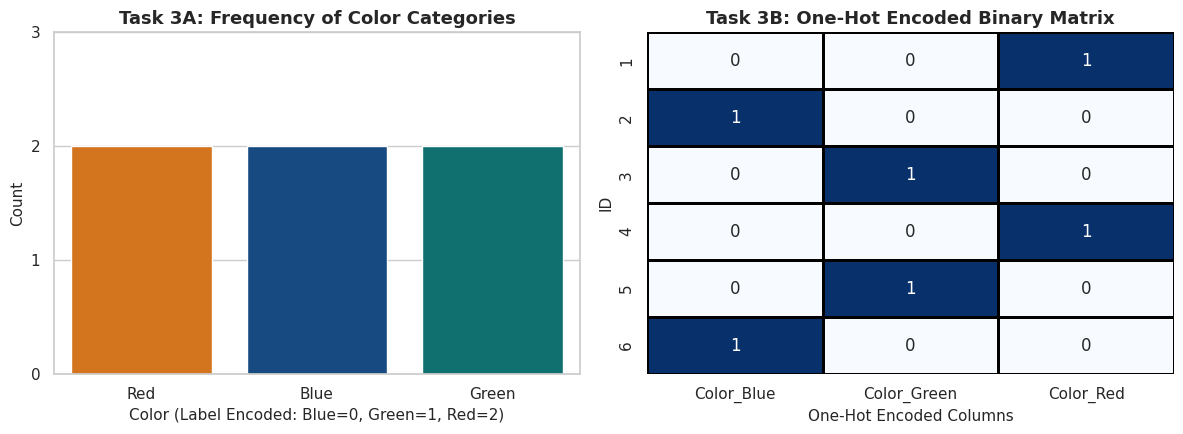

In [12]:
# ==========================================
# Task 3.3: Plot Categorical Distribution & One-Hot Matrix
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Count plot of the original Color categories
sns.countplot(
    data=df_task3,
    x='Color',
    palette={'Red': '#F17300', 'Blue': '#054A91', 'Green': '#008080'},
    ax=axes[0]
)
axes[0].set_title('Task 3A: Frequency of Color Categories', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Color (Label Encoded: Blue=0, Green=1, Red=2)', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].set_yticks(range(0, 4))

# Plot 2: Heatmap of the One-Hot Encoded binary values
sns.heatmap(
    df_onehot_encoded.set_index('ID'),
    annot=True,
    cmap='Blues',
    cbar=False,
    linewidths=1,
    linecolor='black',
    ax=axes[1]
)
axes[1].set_title('Task 3B: One-Hot Encoded Binary Matrix', fontsize=13, fontweight='bold')
axes[1].set_xlabel('One-Hot Encoded Columns', fontsize=11)
axes[1].set_ylabel('ID', fontsize=11)

# Display the plots
plt.tight_layout()
plt.show()

## Task 4

In [13]:
# ==========================================
# Task 4.1: Create DataFrame and Identify Missing Values
# ==========================================

data_task4 = {
    'ID': [1, 2, 3, 4, 5],
    'Name': ['Alex', 'Ben', 'Chris', 'Dana', 'Eva'],
    'Age': [25, np.nan, 30, 28, 35],
    'Gender': ['Male', 'Male', np.nan, 'Female', 'Female'],
    'Salary': [50000, 60000, 70000, np.nan, 80000]
}

# Create the Pandas DataFrame
df_task4 = pd.DataFrame(data_task4)

print("Task 4 - Initial Dataset with Missing Values:")
display(df_task4)
print("-" * 50)

# Identify the count of missing values in each column
missing_counts = df_task4.isnull().sum()
missing_df = pd.DataFrame({
    'Column Name': missing_counts.index,
    'Missing Values Count': missing_counts.values
})

print("Missing Values Count per Column:")
display(missing_df)

Task 4 - Initial Dataset with Missing Values:


,ID,Name,Age,Gender,Salary
0,1,Alex,25.0,Male,50000.0
1,2,Ben,NaN,Male,60000.0
2,3,Chris,30.0,NaN,70000.0
3,4,Dana,28.0,Female,NaN
4,5,Eva,35.0,Female,80000.0


--------------------------------------------------
Missing Values Count per Column:


,Column Name,Missing Values Count
0,ID,0
1,Name,0
2,Age,1
3,Gender,1
4,Salary,1


In [14]:
# ==========================================
# Task 4.2: Impute Missing Values and Display Cleaned Dataset
# ==========================================

df_imputed = df_task4.copy()

# 1. Impute numerical columns ('Age' and 'Salary') using their Mean
age_mean = df_imputed['Age'].mean()
salary_mean = df_imputed['Salary'].mean()

df_imputed['Age'] = df_imputed['Age'].fillna(age_mean)
df_imputed['Salary'] = df_imputed['Salary'].fillna(salary_mean)

# 2. Impute categorical column ('Gender') using its Mode
# Note: Both 'Male' and 'Female' appear twice; .mode()[0] selects the first mode ('Female')
gender_mode = df_imputed['Gender'].mode()[0]
df_imputed['Gender'] = df_imputed['Gender'].fillna(gender_mode)

print(f"Imputed Values -> Age Mean: {age_mean}, Salary Mean: {salary_mean}, Gender Mode: '{gender_mode}'")
print("-" * 65)

print("Task 4 - Cleaned Dataset (After Imputation):")
display(df_imputed)

Imputed Values -> Age Mean: 29.5, Salary Mean: 65000.0, Gender Mode: 'Female'
-----------------------------------------------------------------
Task 4 - Cleaned Dataset (After Imputation):


,ID,Name,Age,Gender,Salary
0,1,Alex,25.0,Male,50000.0
1,2,Ben,29.5,Male,60000.0
2,3,Chris,30.0,Female,70000.0
3,4,Dana,28.0,Female,65000.0
4,5,Eva,35.0,Female,80000.0


In [15]:
# ==========================================
# Task 4.3: Demonstrate dropna() for Rows and Columns
# ==========================================
# 1. Drop rows that contain any missing values (default: axis=0)
df_dropped_rows = df_task4.dropna()

print("Dataset after dropping ROWS with missing values (dropna(axis=0)):")
display(df_dropped_rows)
print("-" * 65)

# 2. Drop columns that contain any missing values (axis=1)
df_dropped_cols = df_task4.dropna(axis=1)

print("Dataset after dropping COLUMNS with missing values (dropna(axis=1)):")
display(df_dropped_cols)


Dataset after dropping ROWS with missing values (dropna(axis=0)):


,ID,Name,Age,Gender,Salary
0,1,Alex,25.0,Male,50000.0
4,5,Eva,35.0,Female,80000.0


-----------------------------------------------------------------
Dataset after dropping COLUMNS with missing values (dropna(axis=1)):


,ID,Name
0,1,Alex
1,2,Ben
2,3,Chris
3,4,Dana
4,5,Eva


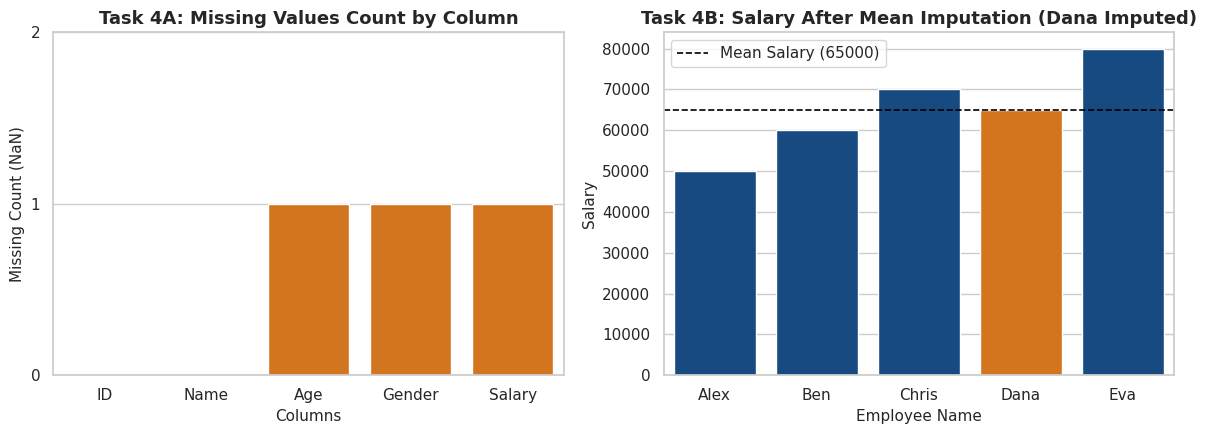

In [16]:
# ==========================================
# Task 4.4: Plot Missing Values & Imputed Salary Comparison
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Bar plot of Missing Values count per column before imputation
sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values,
    palette=['#DBE4EE', '#DBE4EE', '#F17300', '#F17300', '#F17300'],
    ax=axes[0]
)
axes[0].set_title('Task 4A: Missing Values Count by Column', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Columns', fontsize=11)
axes[0].set_ylabel('Missing Count (NaN)', fontsize=11)
axes[0].set_yticks([0, 1, 2])

# Plot 2: Salary distribution after Mean Imputation (highlighting Dana's imputed salary)
bar_colors = ['#054A91' if not pd.isna(sal) else '#F17300' for sal in df_task4['Salary']]
sns.barplot(
    x=df_imputed['Name'],
    y=df_imputed['Salary'],
    palette=bar_colors,
    ax=axes[1]
)
axes[1].axhline(salary_mean, color='black', linestyle='--', linewidth=1.2, label=f'Mean Salary ({salary_mean:.0f})')
axes[1].set_title('Task 4B: Salary After Mean Imputation (Dana Imputed)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Employee Name', fontsize=11)
axes[1].set_ylabel('Salary', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()


## Task 5


Task 5 - Initial Dataset:


,ID,Gender,Age,Salary,Experience
0,1,Male,25,50000,2
1,2,Female,30,60000,5
2,3,Male,22,45000,1
3,4,Female,35,70000,8
4,5,Male,40,80000,10
5,6,Female,28,55000,3
6,7,Male,32,62000,6
7,8,Female,45,90000,12


------------------------------------------------------------------


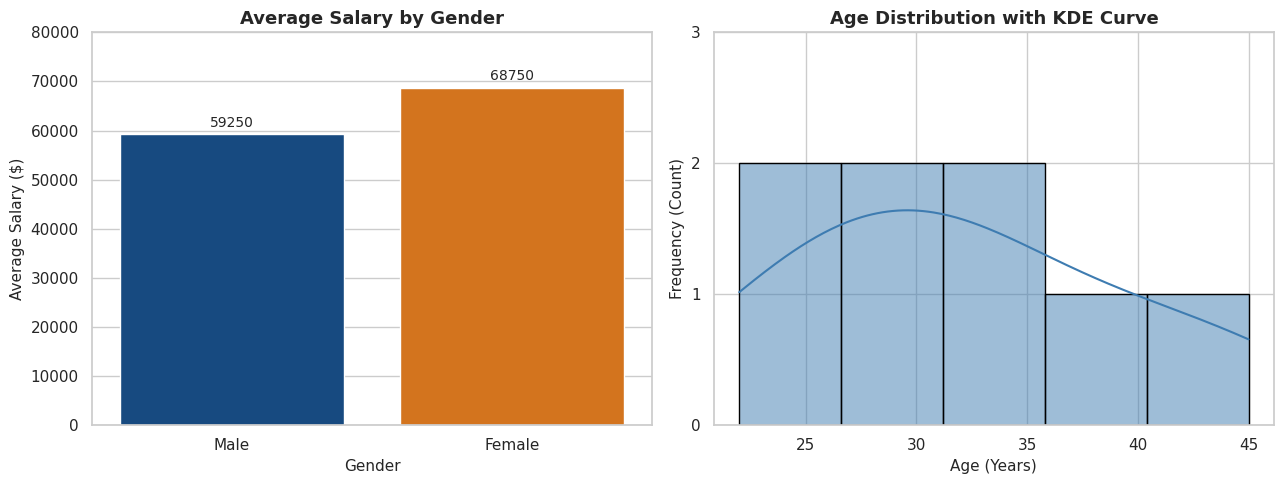

In [17]:

data_task5 = {
    'ID': [1, 2, 3, 4, 5, 6, 7, 8],
    'Gender': ['Male', 'Female', 'Male', 'Female', 'Male', 'Female', 'Male', 'Female'],
    'Age': [25, 30, 22, 35, 40, 28, 32, 45],
    'Salary': [50000, 60000, 45000, 70000, 80000, 55000, 62000, 90000],
    'Experience': [2, 5, 1, 8, 10, 3, 6, 12]
}

df_task5 = pd.DataFrame(data_task5)

print("Task 5 - Initial Dataset:")
display(df_task5)
print("-" * 66)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Task 5.2: Create a bar plot of average Salary by Gender using sns.barplot()
sns.barplot(
    data=df_task5,
    x='Gender',
    y='Salary',
    estimator='mean',
    errorbar=None, # Removes confidence interval lines for a cleaner look
    palette={'Male': '#054A91', 'Female': '#F17300'},
    ax=axes[0]
)
axes[0].set_title('Average Salary by Gender', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Gender', fontsize=11)
axes[0].set_ylabel('Average Salary ($)', fontsize=11)

# Add exact average values on top of the bars for better readability
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', fontsize=10, padding=3)
axes[0].set_ylim(0, 80000)

sns.histplot(
    data=df_task5,
    x='Age',
    bins=5,
    kde=True,
    color='#3E7CB1',
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title('Age Distribution with KDE Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Age (Years)', fontsize=11)
axes[1].set_ylabel('Frequency (Count)', fontsize=11)
axes[1].set_yticks(range(0, 4))

plt.tight_layout()
plt.show()


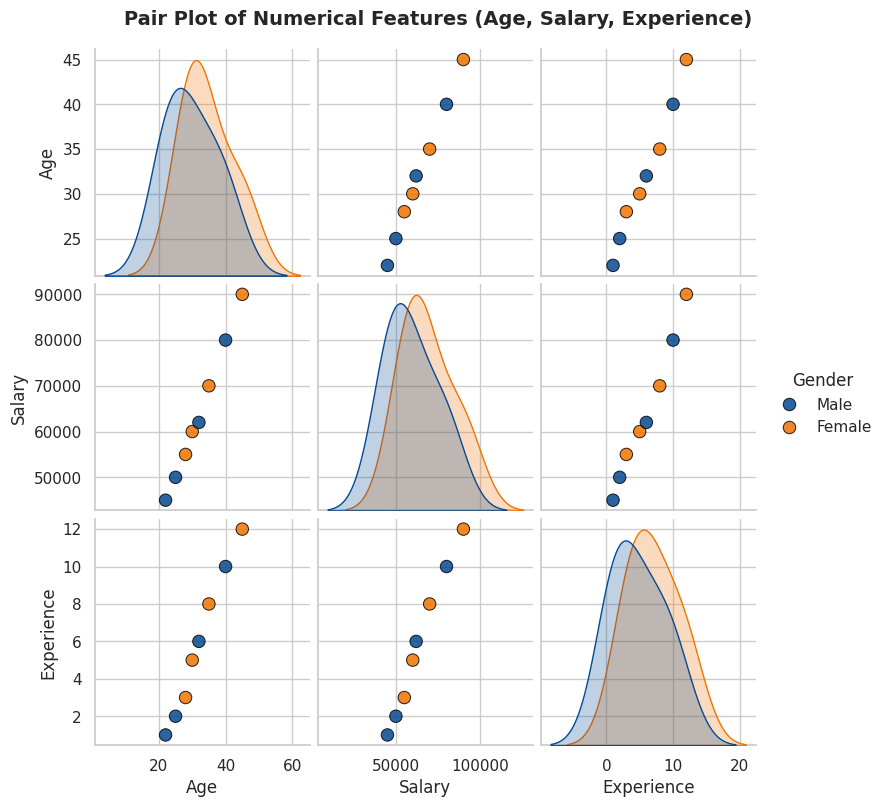

In [18]:

numerical_cols = ['Age', 'Salary', 'Experience', 'Gender']

pair_plot = sns.pairplot(
    df_task5[numerical_cols], # 3 collumn 1 sathy
    hue='Gender',
    palette={'Male': '#054A91', 'Female': '#F17300'},
    diag_kind='kde',
    plot_kws={'s': 80, 'edgecolor': 'black', 'alpha': 0.85},
    height=2.6
)

# Add an overall title at the top of the Pair Plot
pair_plot.fig.suptitle('Pair Plot of Numerical Features (Age, Salary, Experience)', y=1.03, fontsize=14, fontweight='bold')
plt.show()


## Task 6


In [19]:
# ==========================================
# Task 6.1: Create DataFrame and Separate Input Features
# ==========================================

data_task6_7 = {
    'ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    'Age': [29, 34, 37, 41, 45, 31, 39, 43, 48, 50, 52, 55, 58, 47, 60],
    'RestingBP': [120, 118, 125, 130, 128, 115, 122, 132, 135, 140, 138, 145, 150, 142, 155],
    'Cholesterol': [180, 190, 205, 210, 220, 175, 198, 215, 235, 245, 230, 250, 265, 240, 280],
    'MaxHR': [175, 168, 165, 160, 155, 180, 170, 158, 150, 145, 148, 140, 138, 152, 130],
    'Target': [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
}

df_pca = pd.DataFrame(data_task6_7)

print("Task 6 & 7 - Initial Dataset:")
display(df_pca)
print("-" * 65)

# Select only Age, RestingBP, Cholesterol, and MaxHR as input features (exclude ID and Target)
feature_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']
X = df_pca[feature_cols]
y = df_pca['Target'] # Stored separately ONLY for coloring points in plots

# ==========================================
# Task 6.2: Standardize Features and Apply PCA
# ==========================================
# Standardize the input features (mean = 0, variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA across all 4 components to inspect explained variance
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

# Calculate individual and cumulative explained variance ratios
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Create a summary DataFrame for variance explanation
pca_summary_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(feature_cols))],
    'Explained Variance Ratio': np.round(explained_var, 4),
    'Explained Variance (%)': np.round(explained_var * 100, 2),
    'Cumulative Variance (%)': np.round(cumulative_var * 100, 2)
})

print("Task 6 - PCA Explained Variance Summary:")
display(pca_summary_df)

# Identify the minimum number of components needed to explain at least 95% variance
n_components_95 = np.argmax(cumulative_var >= 0.95) + 1
print(f"\nNumber of components needed to explain at least 95% of the variance: {n_components_95} (PC1 alone explains {cumulative_var[0]*100:.2f}%)")

Task 6 & 7 - Initial Dataset:


,ID,Age,RestingBP,Cholesterol,MaxHR,Target
0,1,29,120,180,175,0
1,2,34,118,190,168,0
2,3,37,125,205,165,0
3,4,41,130,210,160,0
4,5,45,128,220,155,0
5,6,31,115,175,180,0
6,7,39,122,198,170,0
7,8,43,132,215,158,0
8,9,48,135,235,150,1
9,10,50,140,245,145,1


-----------------------------------------------------------------
Task 6 - PCA Explained Variance Summary:


,Principal Component,Explained Variance Ratio,Explained Variance (%),Cumulative Variance (%)
0,PC1,0.9813,98.13,98.13
1,PC2,0.0112,1.12,99.25
2,PC3,0.0050,0.50,99.75
3,PC4,0.0025,0.25,100.00



Number of components needed to explain at least 95% of the variance: 1 (PC1 alone explains 98.13%)


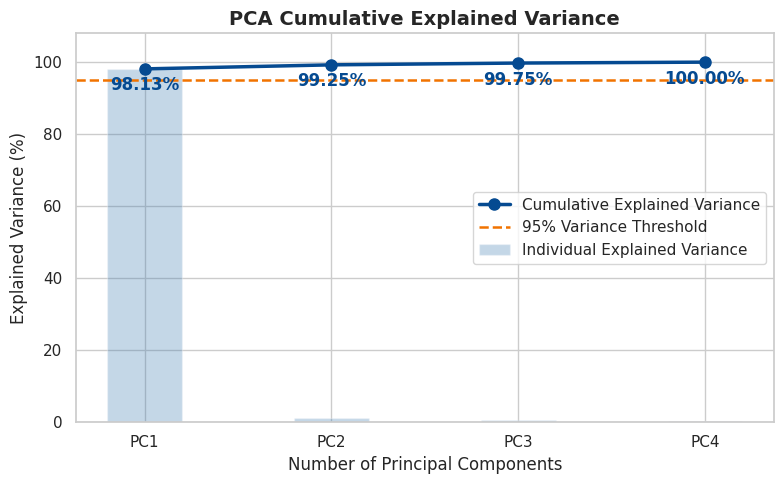

In [20]:
# ==========================================
# Task 6.3: Plot Cumulative Explained Variance
# ==========================================
plt.figure(figsize=(8, 5))

# Component numbers (1 to 4)
components = range(1, len(cumulative_var) + 1)

plt.plot(
    components,
    cumulative_var * 100,
    marker='o',
    color='#054A91',
    linewidth=2.5,
    markersize=8,
    label='Cumulative Explained Variance'
)

plt.bar(
    components,
    explained_var * 100,
    alpha=0.3,
    color='#3E7CB1',
    width=0.4,
    label='Individual Explained Variance'
)

# Add a horizontal threshold line at 95% variance
plt.axhline(y=95, color='#F17300', linestyle='--', linewidth=1.8, label='95% Variance Threshold')

for i, txt in enumerate(cumulative_var * 100):
    plt.annotate(f"{txt:.2f}%", (components[i], cumulative_var[i] * 100 - 6), ha='center', fontweight='bold', color='#054A91')

# Configure plot titles, axis labels, and ticks
plt.title('PCA Cumulative Explained Variance', fontsize=14, fontweight='bold')
plt.xlabel('Number of Principal Components', fontsize=12)
plt.ylabel('Explained Variance (%)', fontsize=12)
plt.xticks(components, [f'PC{i}' for i in components])
plt.ylim(0, 108)
plt.legend(loc='center right')

plt.tight_layout()
plt.show()

First Two Principal Components Dataset:


,PC1,PC2,Target
0,-2.828134,0.376234,0
1,-2.220093,-0.155947,0
2,-1.393488,0.101517,0
3,-0.695991,0.068121,0
4,-0.214548,-0.358156,0


-------------------------------------------------------


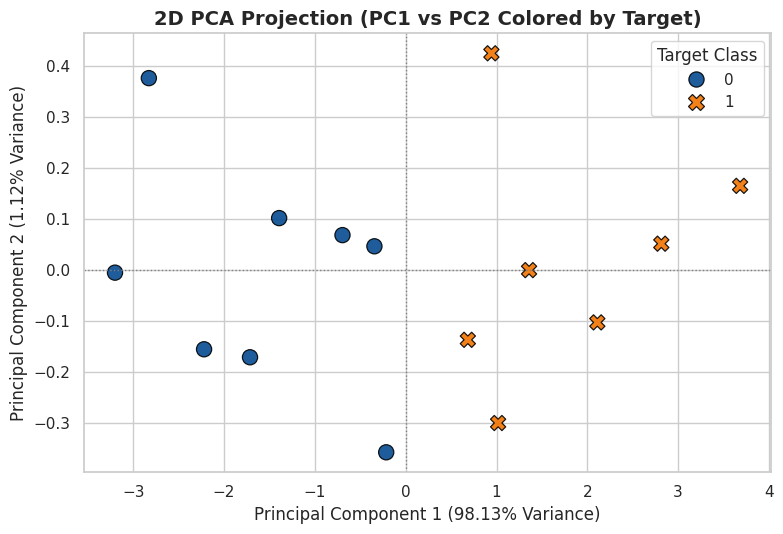

In [21]:
# ==========================================
# Task 6.4: Plot the First Two Principal Components (PC1 vs PC2)
# ==========================================
# Create a DataFrame with the first two principal components and the Target label for plotting
df_pca_2d = pd.DataFrame({
    'PC1': X_pca_full[:, 0],
    'PC2': X_pca_full[:, 1],
    'Target': y
})

print("First Two Principal Components Dataset:")
display(df_pca_2d.head()) # Displaying first 5 rows for verification
print("-" * 55)

# Plot PC1 vs PC2, coloring points by Target
plt.figure(figsize=(8, 5.5))

sns.scatterplot(
    data=df_pca_2d,
    x='PC1',
    y='PC2',
    hue='Target',
    style='Target',
    palette={0: '#054A91', 1: '#F17300'},
    s=120,
    edgecolor='black',
    alpha=0.9
)

# Add reference lines at origin (0, 0)
plt.axvline(0, color='gray', linestyle=':', linewidth=1)
plt.axhline(0, color='gray', linestyle=':', linewidth=1)

plt.title('2D PCA Projection (PC1 vs PC2 Colored by Target)', fontsize=14, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.2f}% Variance)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.2f}% Variance)', fontsize=12)
plt.legend(title='Target Class', loc='best')

plt.tight_layout()
plt.show()


## Task 7


In [22]:
from sklearn.manifold import TSNE

# ==========================================
# Task 7.1: Prepare Standardized Input Features for t-SNE
# ==========================================
# Reuse the 4 input features (Age, RestingBP, Cholesterol, MaxHR) from Task 6
# Note: X_scaled is already standardized using StandardScaler() in Task 6.2
print("Task 7.1 - Input Features Shape (Rows, Features):", X_scaled.shape)
print("-" * 60)

# ==========================================
# Task 7.2: Apply t-SNE to Reduce Dimensions to 2D
# ==========================================
# Initialize TSNE with 2 components
tsne = TSNE(n_components=2, perplexity=5, random_state=42)

X_tsne = tsne.fit_transform(X_scaled)

df_tsne = pd.DataFrame({
    'ID': df_pca['ID'],
    't-SNE 1': np.round(X_tsne[:, 0], 4),
    't-SNE 2': np.round(X_tsne[:, 1], 4),
    'Target': y
})

print("Task 7.2 - 2D t-SNE Transformed Dataset:")
display(df_tsne)

Task 7.1 - Input Features Shape (Rows, Features): (15, 4)
------------------------------------------------------------
Task 7.2 - 2D t-SNE Transformed Dataset:


,ID,t-SNE 1,t-SNE 2,Target
0,1,63.449600,-123.272202,0
1,2,53.585999,-102.652802,0
2,3,40.636700,-77.646698,0
3,4,27.441601,-54.670200,0
4,5,9.282100,-35.010601,0
5,6,80.199699,-110.569702,0
6,7,60.668301,-81.622803,0
7,8,29.705299,-34.370800,0
8,9,-8.578300,8.914700,1
9,10,-22.354700,30.286200,1


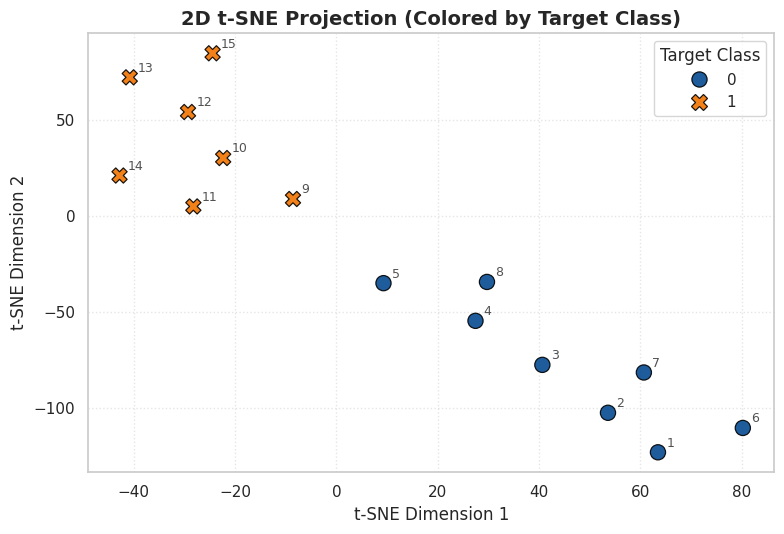

In [25]:
# ==========================================
# Task 7.3: Plot the 2D t-SNE Results Colored by Target
# ==========================================
plt.figure(figsize=(8, 5.5))

# Create a 2D scatter plot of t-SNE Component 1 vs t-SNE Component 2
sns.scatterplot(
    data=df_tsne,
    x='t-SNE 1',
    y='t-SNE 2',
    hue='Target',
    style='Target',
    palette={0: '#054A91', 1: '#F17300'},
    s=120,
    edgecolor='black',
    alpha=0.9
)

# Optional: Annotate each point with its ID to easily track local neighbors
for i in range(len(df_tsne)):
    plt.annotate(
        df_tsne['ID'][i],
        (df_tsne['t-SNE 1'][i], df_tsne['t-SNE 2'][i]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=9,
        alpha=0.8
    )

# Add plot title, axis labels, and legend
plt.title('2D t-SNE Projection (Colored by Target Class)', fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=12)
plt.ylabel('t-SNE Dimension 2', fontsize=12)
plt.legend(title='Target Class', loc='best')
plt.grid(True, linestyle=':', alpha=0.5)

# Display the plot
plt.tight_layout()
plt.show()

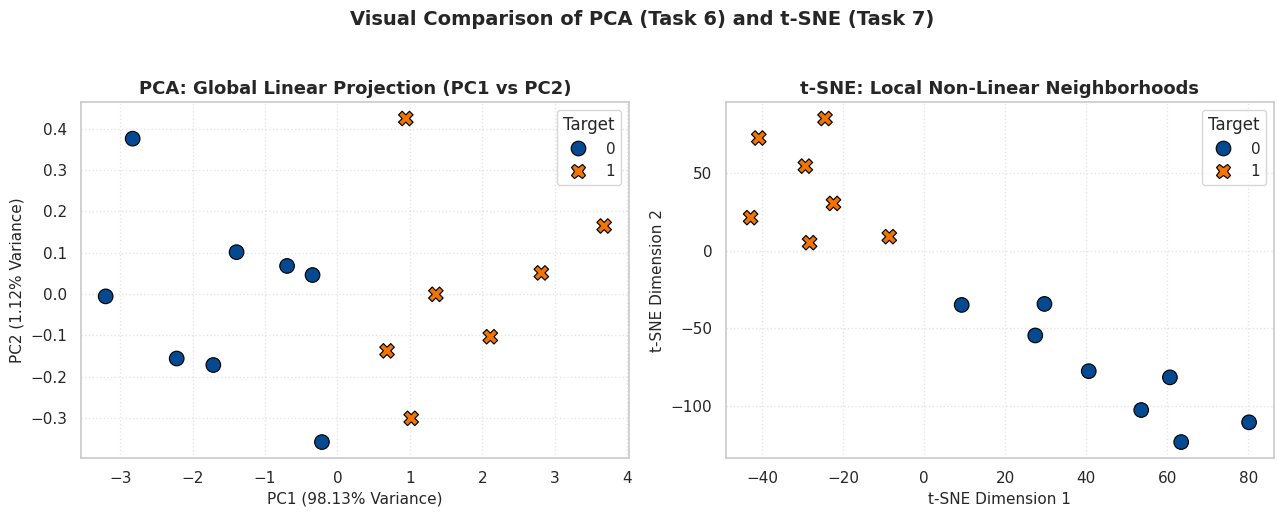

In [26]:
# ==========================================
# Task 7.4 (Optional Bonus Plot): Side-by-Side Comparison of PCA vs t-SNE
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: 2D PCA Projection
sns.scatterplot(
    data=df_pca_2d, x='PC1', y='PC2', hue='Target', style='Target',
    palette={0: '#054A91', 1: '#F17300'}, s=110, edgecolor='black', ax=axes[0]
)
axes[0].set_title('PCA: Global Linear Projection (PC1 vs PC2)', fontsize=13, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({explained_var[0]*100:.2f}% Variance)', fontsize=11)
axes[0].set_ylabel(f'PC2 ({explained_var[1]*100:.2f}% Variance)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.5)

# Right Plot: 2D t-SNE Projection
sns.scatterplot(
    data=df_tsne, x='t-SNE 1', y='t-SNE 2', hue='Target', style='Target',
    palette={0: '#054A91', 1: '#F17300'}, s=110, edgecolor='black', ax=axes[1]
)
axes[1].set_title('t-SNE: Local Non-Linear Neighborhoods', fontsize=13, fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1', fontsize=11)
axes[1].set_ylabel('t-SNE Dimension 2', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Visual Comparison of PCA (Task 6) and t-SNE (Task 7)', y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()